<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/pendulum_bug_oscillation_rotation_slow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Transition from rotation to oscillation (and back).

<>:184: SyntaxWarning: invalid escape sequence '\c'
<>:184: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_616/2563261072.py:184: SyntaxWarning: invalid escape sequence '\c'
  ic_str = f"$\\theta_0 = {th0_deg:.0f}^\circ$, $\\dot{{\\theta}}_0 = {om0:.1f}$ rad/s, $|v_b| = {v_b_slow}$ m/s"


Simulating Case 1: Inward Only (Moderate J)...
Simulating Case 2: Inward Only (Large J)...
Simulating Case 3: Inward-Outward (Moderate J)...
Simulating Case 4: Inward-Outward (Large J)...


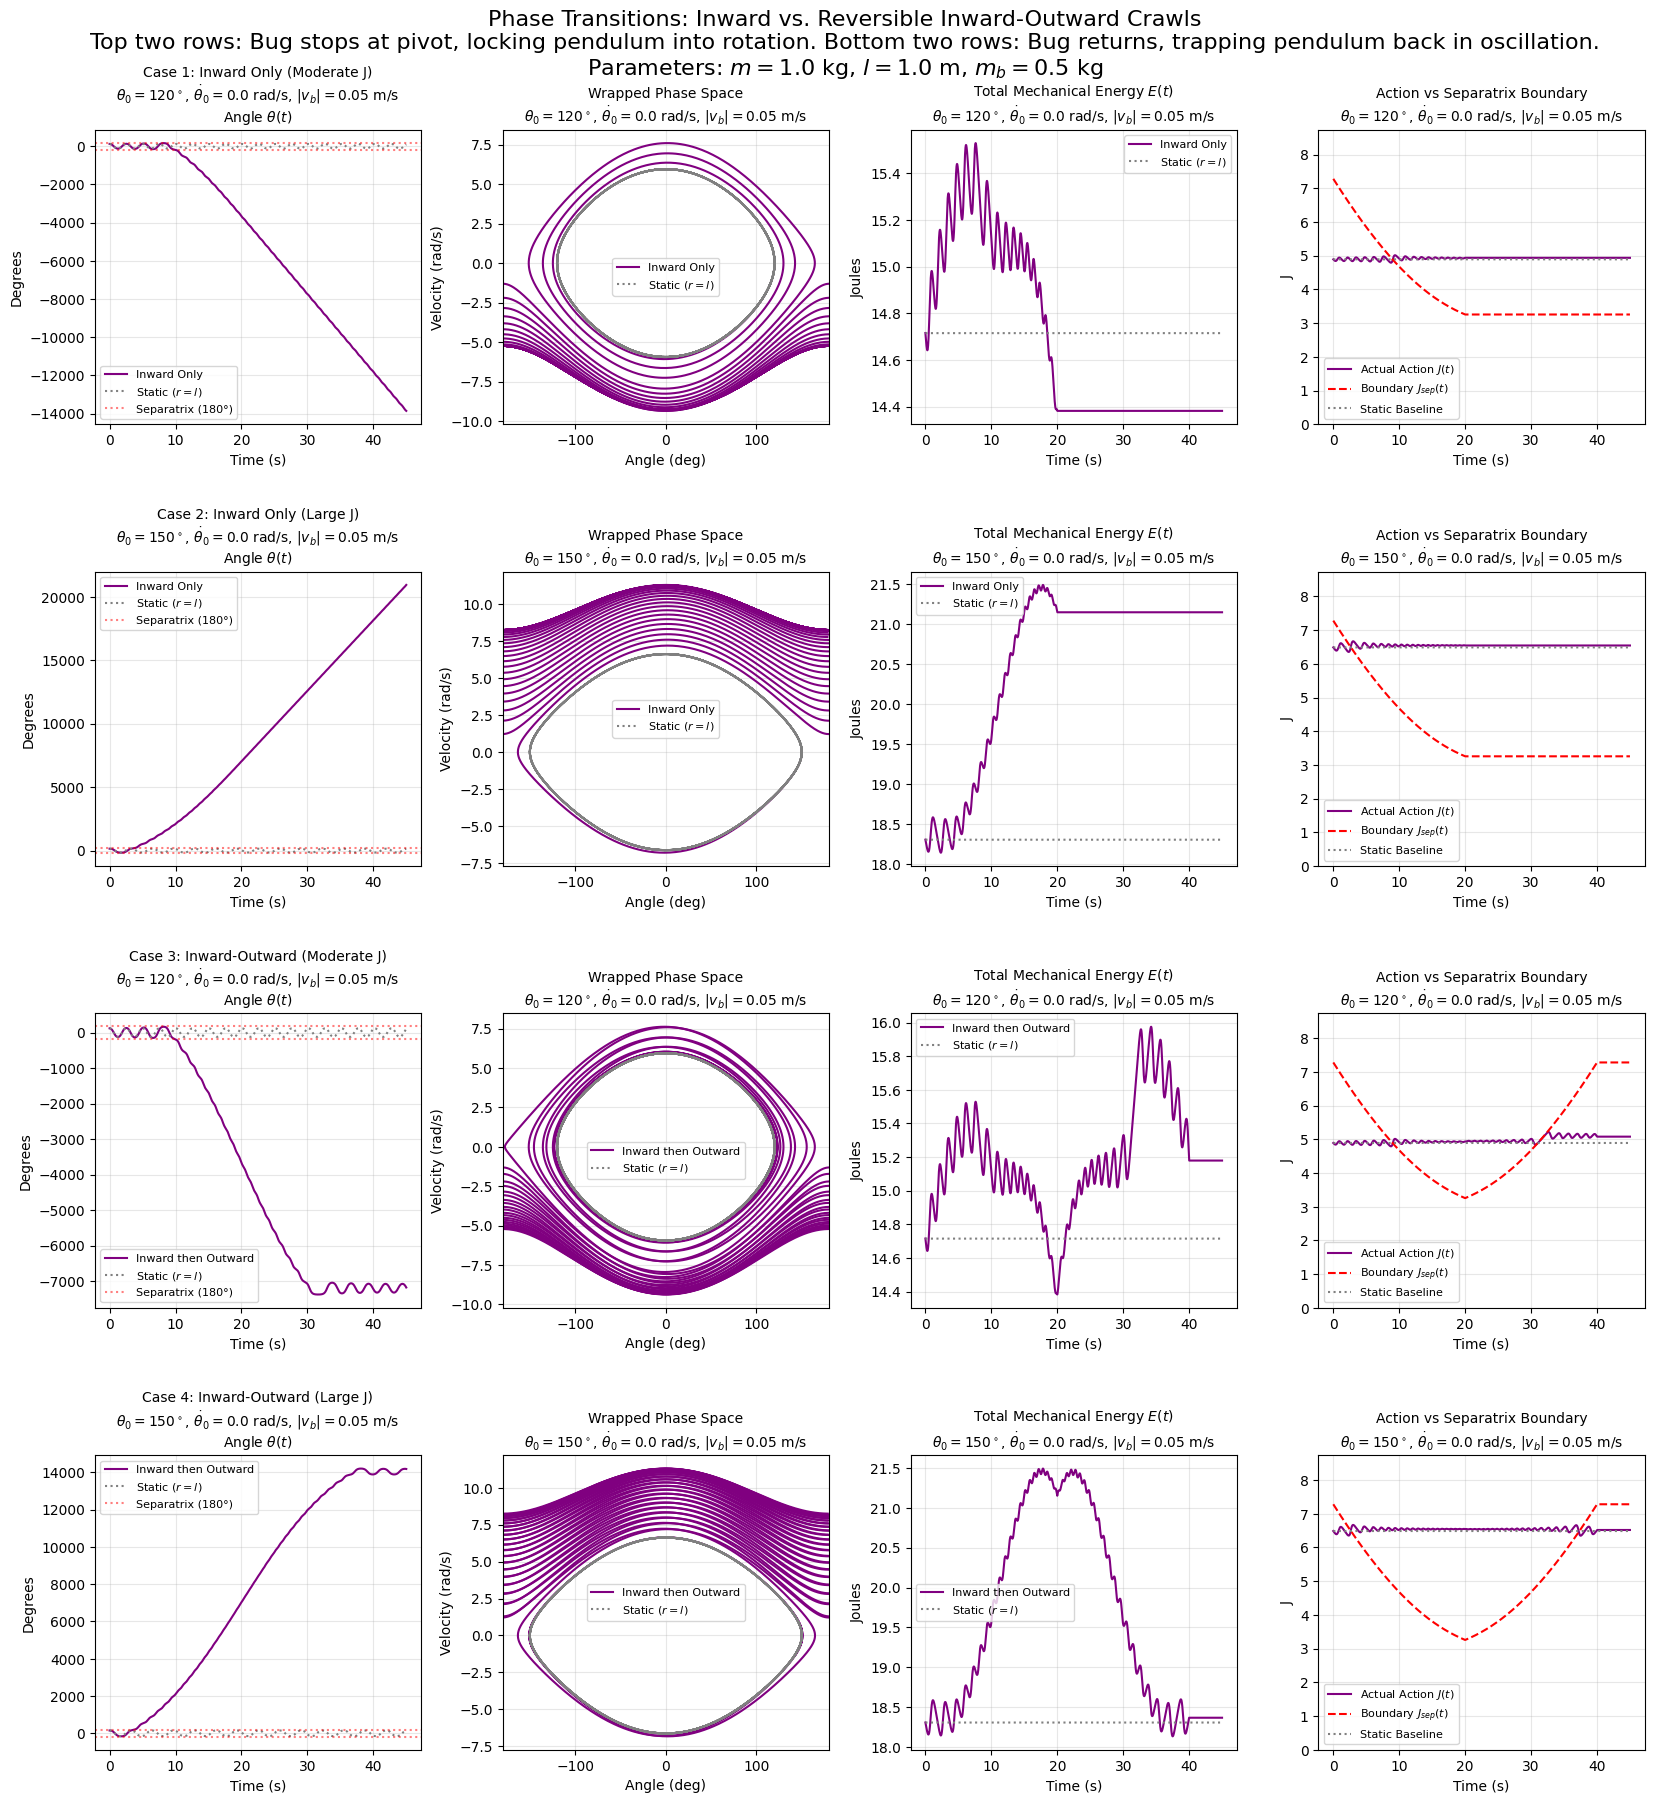

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import warnings

# Suppress integration warnings during separatrix crossing
warnings.filterwarnings("ignore")

def get_kinematics(t, v_b, p, mode):
    """
    Calculates the bug's position r(t) and velocity r_dot(t).
    """
    l = p['l']

    if mode == 'static':
        return l, 0.0 # Keeping static bug at r=l for the baseline

    elif mode == 'pingpong':
        s = v_b * t
        mod_s = s % (2 * l)
        if mod_s < l:
            return mod_s, v_b          # Crawling down
        else:
            return 2 * l - mod_s, -v_b # Crawling up

    elif mode == 'harmonic':
        # To match the ping-pong round trip time (T = 2l / v_b),
        # the harmonic angular frequency must be Omega = 2*pi / T = pi * v_b / l
        omega_b = np.pi * v_b / l if v_b > 0 else 0
        r = (l / 2) * (1 - np.cos(omega_b * t))
        r_dot = (l / 2) * omega_b * np.sin(omega_b * t)
        return r, r_dot

    elif mode == 'inward_slow':
        # Bug starts at end of rod (r=l) and crawls slowly inward to pivot (r=0), and stops.
        r = max(0.0, l - v_b * t)
        r_dot = -v_b if r > 0.0 else 0.0
        return r, r_dot

    elif mode == 'inward_outward_slow':
        # Bug starts at end of rod (r=l), crawls slowly inward to pivot (r=0),
        # and then crawls back outward to the end of the rod (r=l).
        T_half = l / v_b
        if t <= T_half:
            # Crawling Inward
            r = l - v_b * t
            r_dot = -v_b
        elif t <= 2 * T_half:
            # Crawling Outward
            r = v_b * (t - T_half)
            r_dot = v_b
        else:
            # Stopped at the end
            r = l
            r_dot = 0.0
        return max(0.0, min(l, r)), r_dot

def dy_dt(t, y, v_b, p, mode):
    """ Exact Newtonian Equation of Motion. """
    theta, omega = y
    r, r_dot = get_kinematics(t, v_b, p, mode)

    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

    alpha = (- 2 * p['m_b'] * r * r_dot * omega - M_eff * p['g'] * np.sin(theta)) / I
    return np.array([omega, alpha])

def calc_E(y, t, v_b, p, mode):
    """ Total Instantaneous Mechanical Energy E(t). """
    theta, omega = y
    r, r_dot = get_kinematics(t, v_b, p, mode)

    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

    V = M_eff * p['g'] * (1 - np.cos(theta))
    T = 0.5 * I * omega**2 + 0.5 * p['m_b'] * r_dot**2
    return T + V

def calc_J(E, t, v_b, p, mode):
    """ Action J (Adiabatic Invariant, representing actual phase space area). """
    r, _ = get_kinematics(t, v_b, p, mode)
    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r
    max_V = 2 * M_eff * p['g']

    if E < max_V:
        # Oscillating Regime
        val = np.clip(1.0 - E / (M_eff * p['g']), -1.0, 1.0)
        theta_max = np.arccos(val)
        def integrand(theta):
            V = M_eff * p['g'] * (1 - np.cos(theta))
            return np.sqrt(2 * I * max(0.0, E - V))
        res, _ = quad(integrand, 0, theta_max, limit=100)
        return (4 * res) / (2 * np.pi)
    else:
        # Rotating Regime
        def integrand(theta):
            V = M_eff * p['g'] * (1 - np.cos(theta))
            return np.sqrt(2 * I * max(0.0, E - V))
        res, _ = quad(integrand, 0, 2 * np.pi, limit=100)
        return (2 * res) / (2 * np.pi)

def calc_J_sep(t, v_b, p, mode):
    """ Calculates the maximum possible Action for oscillation (The Separatrix Boundary). """
    r, _ = get_kinematics(t, v_b, p, mode)
    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r
    return (8 / np.pi) * np.sqrt(I * M_eff * p['g'])

def solve_rk4(y0, v_b, p, mode, t_span, dt=0.005):
    """ 4th Order Runge-Kutta Integrator. """
    t_vals = np.arange(t_span[0], t_span[1], dt)
    y_vals = np.zeros((len(t_vals), 2))
    y_vals[0] = y0
    for i in range(1, len(t_vals)):
        t = t_vals[i-1]
        y = y_vals[i-1]
        k1 = dy_dt(t, y, v_b, p, mode)
        k2 = dy_dt(t + 0.5*dt, y + 0.5*dt*k1, v_b, p, mode)
        k3 = dy_dt(t + 0.5*dt, y + 0.5*dt*k2, v_b, p, mode)
        k4 = dy_dt(t + dt, y + dt*k3, v_b, p, mode)
        y_vals[i] = y + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)
    return t_vals, y_vals

def plot_phase_space(ax, theta, omega, color, label, linestyle='-'):
    """ Wraps theta to [-pi, pi] and plots phase space without connecting jump lines in degrees. """
    theta_wrap = (theta + np.pi) % (2 * np.pi) - np.pi
    jumps = np.where(np.abs(np.diff(theta_wrap)) > np.pi)[0] + 1

    theta_split = np.split(theta_wrap, jumps)
    omega_split = np.split(omega, jumps)

    for i in range(len(theta_split)):
        lbl = label if i == 0 else None
        ax.plot(np.rad2deg(theta_split[i]), omega_split[i], color=color, label=lbl, linestyle=linestyle)

def main():
    # Base Physical Parameters
    p = {'m': 1.0, 'l': 1.0, 'm_b': 0.5, 'g': 9.81}
    t_span = [0, 45] # 20s in, 20s out, 5s rest at the end.

    # Slow bug velocity (Adiabatic Limit)
    v_b_slow = 0.05

    cases = [
        {
            "name": "Case 1: Inward Only (Moderate J)",
            "y0": [120 * np.pi/180, 0.0],
            "mode": "inward_slow",
            "label": "Inward Only"
        },
        {
            "name": "Case 2: Inward Only (Large J)",
            "y0": [150 * np.pi/180, 0.0],
            "mode": "inward_slow",
            "label": "Inward Only"
        },
        {
            "name": "Case 3: Inward-Outward (Moderate J)",
            "y0": [120 * np.pi/180, 0.0],
            "mode": "inward_outward_slow",
            "label": "Inward then Outward"
        },
        {
            "name": "Case 4: Inward-Outward (Large J)",
            "y0": [150 * np.pi/180, 0.0],
            "mode": "inward_outward_slow",
            "label": "Inward then Outward"
        }
    ]

    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    # Adjusted spacing to prevent labels and titles from overlapping
    plt.subplots_adjust(hspace=0.5, wspace=0.25, top=0.92)

    for i, case in enumerate(cases):
        print(f"Simulating {case['name']}...")

        mode = case['mode']
        th0_deg = np.rad2deg(case['y0'][0])
        om0 = case['y0'][1]
        ic_str = f"$\\theta_0 = {th0_deg:.0f}^\circ$, $\\dot{{\\theta}}_0 = {om0:.1f}$ rad/s, $|v_b| = {v_b_slow}$ m/s"

        # 1. Moving Bug
        t_m, y_m = solve_rk4(case['y0'], v_b_slow, p, mode, t_span)
        E_m = [calc_E(y, t, v_b_slow, p, mode) for y, t in zip(y_m, t_m)]
        J_m = [calc_J(E, t, v_b_slow, p, mode) for E, t in zip(E_m, t_m)]
        J_sep_m = [calc_J_sep(t, v_b_slow, p, mode) for t in t_m] # The Analytical Boundary

        # 2. Static Baseline (Bug stuck at end of rod r=l)
        t_s, y_s = solve_rk4(case['y0'], 0.0, p, 'static', t_span)
        E_s = [calc_E(y, t, 0.0, p, 'static') for y, t in zip(y_s, t_s)]
        J_s = [calc_J(E, t, 0.0, p, 'static') for E, t in zip(E_s, t_s)]

        # 1. Plot Theta (Unwrapped)
        ax = axes[i, 0]
        ax.plot(t_m, np.rad2deg(y_m[:, 0]), label=case['label'], color='purple')
        ax.plot(t_s, np.rad2deg(y_s[:, 0]), label='Static ($r=l$)', color='gray', linestyle=':')
        ax.set_title(f"{case['name']}\n{ic_str}\nAngle $\\theta(t)$", fontsize=10)
        ax.set_ylabel("Degrees")
        ax.set_xlabel("Time (s)")
        ax.axhline(180, color='red', linestyle=':', alpha=0.5, label='Separatrix (180°)')
        ax.axhline(-180, color='red', linestyle=':', alpha=0.5)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

        # 2. Plot Phase Space
        ax = axes[i, 1]
        plot_phase_space(ax, y_m[:, 0], y_m[:, 1], 'purple', case['label'])
        plot_phase_space(ax, y_s[:, 0], y_s[:, 1], 'gray', 'Static ($r=l$)', linestyle=':')
        ax.set_title(f"Wrapped Phase Space\n{ic_str}", fontsize=10)
        ax.set_xlim(-180, 180)
        ax.set_xlabel("Angle (deg)")
        ax.set_ylabel("Velocity (rad/s)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

        # 3. Plot Energy
        ax = axes[i, 2]
        ax.plot(t_m, E_m, color='purple', label=case['label'])
        ax.plot(t_s, E_s, color='gray', linestyle=':', label='Static ($r=l$)')
        ax.set_title(f"Total Mechanical Energy $E(t)$\n{ic_str}", fontsize=10)
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Joules")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

        # 4. Plot Action J alongside the Analytical Separatrix Boundary
        ax = axes[i, 3]
        ax.plot(t_m, J_m, color='purple', label='Actual Action $J(t)$')
        ax.plot(t_m, J_sep_m, color='red', linestyle='--', label='Boundary $J_{sep}(t)$')
        ax.plot(t_s, J_s, color='gray', linestyle=':', label='Static Baseline')
        ax.set_title(f"Action vs Separatrix Boundary\n{ic_str}", fontsize=10)
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("J")
        ax.legend(fontsize=8, loc='lower left')
        ax.grid(alpha=0.3)

        # Set Y-axis to start at 0 so the collapsing boundary and intersection are clear
        ax.set_ylim(0, max(J_sep_m) * 1.2)

    plt.suptitle("Phase Transitions: Inward vs. Reversible Inward-Outward Crawls\n"
                 "Top two rows: Bug stops at pivot, locking pendulum into rotation. Bottom two rows: Bug returns, trapping pendulum back in oscillation.\n"
                 f"Parameters: $m={p['m']}$ kg, $l={p['l']}$ m, $m_b={p['m_b']}$ kg",
                 fontsize=16, y=0.98)
    plt.show()

if __name__ == "__main__":
    main()